# Preparing ETFs

This notebook:

- loads the daily OHLCV data for all ETF symbols,
- runs basic sanity checks on dates, missing values, and zeros,
- applies cleaning steps to the price columns (`Open`, `Close`, `Adj Close`, `Volume`, `High`, `Low` ).




In [1]:
from pathlib import Path
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries And Useful Files

In [2]:
from src.utils.loading_data import *
from src.utils.data_inspection import *
from src.utils.data_inspection_viz import *
from src.utils.metadata_enrich import *
from src.utils.data_cleaning import *



# Loading ETFs

In [3]:

# Folder containing all stock CSVs
etfs_dir = Path("data/etfs")

# Dictionary to hold all loaded DataFrames
all_etfs = {}

# Loop over every CSV file in the folder
for csv_file in sorted(etfs_dir.glob("*.csv")):
    symbol = csv_file.stem  # e.g. AAPL.csv → AAPL
    df = load_symbol_from_dir(etfs_dir, symbol)
    all_etfs[symbol] = df
    print(f"Loaded {symbol}: {len(df)} rows")

print(f"\n✅ Loaded {len(all_etfs)} etf symbols total.")


Loaded AAAU: 410 rows
Loaded AADR: 2442 rows
Loaded AAXJ: 2927 rows
Loaded ABEQ: 50 rows
Loaded ACES: 443 rows
Loaded ACIO: 185 rows
Loaded ACSG: 332 rows
Loaded ACSI: 855 rows
Loaded ACT: 578 rows
Loaded ACWF: 1238 rows
Loaded ACWI: 3025 rows
Loaded ACWV: 2125 rows
Loaded ACWX: 3023 rows
Loaded ADME: 961 rows
Loaded ADRE: 4374 rows
Loaded AESR: 73 rows
Loaded AFIF: 377 rows
Loaded AFK: 2951 rows
Loaded AFLG: 82 rows
Loaded AFMC: 82 rows
Loaded AFSM: 82 rows
Loaded AFTY: 1274 rows
Loaded AGG: 4156 rows
Loaded AGGP: 981 rows
Loaded AGGY: 1192 rows
Loaded AGND: 1582 rows
Loaded AGQ: 2850 rows
Loaded AGT: 1106 rows
Loaded AGZ: 2866 rows
Loaded AGZD: 1582 rows
Loaded AIA: 3112 rows
Loaded AIEQ: 617 rows
Loaded AIIQ: 459 rows
Loaded AIQ: 473 rows
Loaded AIRR: 1527 rows
Loaded ALFA: 1972 rows
Loaded ALTS: 1379 rows
Loaded ALTY: 1189 rows
Loaded AMCA: 666 rows
Loaded AMLP: 2417 rows
Loaded AMOM: 219 rows
Loaded AMZA: 1384 rows
Loaded ANGL: 2007 rows
Loaded AOA: 2866 rows
Loaded AOK: 2860 rows

## 3. Date sanity checks

In this section we verify the time axis of our etfs data:

- Check that dates inside each symbol are strictly increasing.
- Show the global date range for all etfs.
- Find symbols that end too early (before a chosen cutoff date).
- Plot the distribution of start dates across all symbols.
- Add the column weekday for further use

These checks help us detect symbols with strange or truncated histories
before we start cleaning.


In [4]:
print("\n🔍 Checking if dates of etfs are in increasing order...")

for symbol, df in all_etfs.items():
    if dates_in_increasing_order(df):
        print(f"✅ {symbol}: dates are in increasing order.")
    else:
        print(f"⚠️ {symbol}: dates are NOT in increasing order!")



🔍 Checking if dates of etfs are in increasing order...
✅ AAAU: dates are in increasing order.
✅ AADR: dates are in increasing order.
✅ AAXJ: dates are in increasing order.
✅ ABEQ: dates are in increasing order.
✅ ACES: dates are in increasing order.
✅ ACIO: dates are in increasing order.
✅ ACSG: dates are in increasing order.
✅ ACSI: dates are in increasing order.
✅ ACT: dates are in increasing order.
✅ ACWF: dates are in increasing order.
✅ ACWI: dates are in increasing order.
✅ ACWV: dates are in increasing order.
✅ ACWX: dates are in increasing order.
✅ ADME: dates are in increasing order.
✅ ADRE: dates are in increasing order.
✅ AESR: dates are in increasing order.
✅ AFIF: dates are in increasing order.
✅ AFK: dates are in increasing order.
✅ AFLG: dates are in increasing order.
✅ AFMC: dates are in increasing order.
✅ AFSM: dates are in increasing order.
✅ AFTY: dates are in increasing order.
✅ AGG: dates are in increasing order.
✅ AGGP: dates are in increasing order.
✅ AGGY: dat

In [5]:
show_date_ranges(all_etfs, "stocks")



 Date ranges for all stocks:

AAAU: from 2018-08-15 → 2020-04-01
AADR: from 2010-07-21 → 2020-04-01
AAXJ: from 2008-08-15 → 2020-04-01
ABEQ: from 2020-01-22 → 2020-04-01
ACES: from 2016-01-27 → 2020-04-01
ACIO: from 2019-07-10 → 2020-04-01
ACSG: from 2018-12-06 → 2020-04-01
ACSI: from 2016-11-07 → 2020-04-01
ACT: from 2017-12-13 → 2020-04-01
ACWF: from 2015-05-04 → 2020-04-01
ACWI: from 2008-03-28 → 2020-04-01
ACWV: from 2011-10-20 → 2020-04-01
ACWX: from 2008-04-01 → 2020-04-01
ADME: from 2016-06-08 → 2020-04-01
ADRE: from 2002-11-14 → 2020-04-01
AESR: from 2019-12-17 → 2020-04-01
AFIF: from 2018-10-02 → 2020-04-01
AFK: from 2008-07-14 → 2020-04-01
AFLG: from 2019-12-04 → 2020-04-01
AFMC: from 2019-12-04 → 2020-04-01
AFSM: from 2019-12-04 → 2020-04-01
AFTY: from 2015-03-12 → 2020-04-01
AGG: from 2003-09-29 → 2020-04-01
AGGP: from 2016-05-10 → 2020-04-01
AGGY: from 2015-07-09 → 2020-04-01
AGND: from 2013-12-18 → 2020-04-01
AGQ: from 2008-12-04 → 2020-04-01
AGT: from 2010-11-08 → 2020-

In [6]:
ends_before(all_etfs, "etfs", cutoff_date="2020-04-01")

 The following etfs end before 2020-04-01:
  - FDG


['FDG']

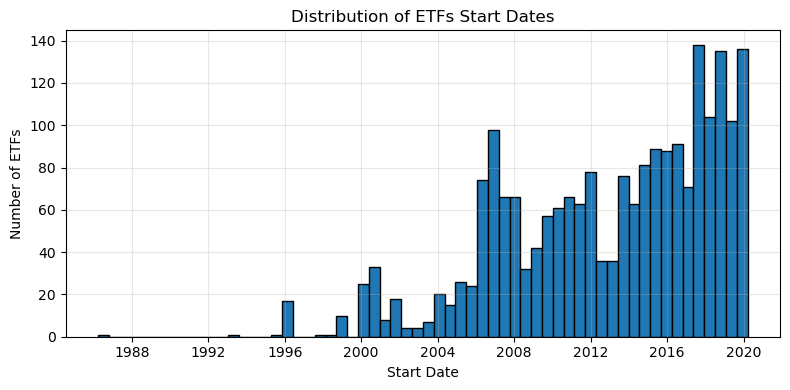

In [7]:
plot_start_date_distribution(all_etfs, "ETFs")

In [8]:
def add_weekday_column(all_stocks, date_col="Date"):
    """
    Add a 'Weekday' column (0=Mon ... 4=Fri) right after the Date column.
    Modifies all_stocks in-place.
    """
    for symbol, df in all_stocks.items():

        # Ensure Date column is datetime
        df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

        # Compute weekday (0=Mon ... 6=Sun, but your data only has 0-4)
        weekday = df[date_col].dt.weekday

        # Position where 'Date' is located
        idx = df.columns.get_loc(date_col)

        # Insert new column right after Date
        df.insert(idx + 1, "Weekday", weekday)
        

add_weekday_column(all_etfs)

## 4. Missing data analysis

Here we look at missing values in the etf time series.

We:

- compute, for each symbol, the fraction of missing values;
- compute overall missing rates for the whole dataset;
- plot how the number of missing entries evolves over time.

This gives an overview of the data quality and shows if certain periods
have more missing data than others.


In [9]:
missing_per_etf, missing_etfs = missing_rates_from_dict(all_etfs)

print(" Missing rates per stock:")
print(missing_per_etf.head())

print("\n Overall missing rates for stocks:")
print(missing_etfs)

 Missing rates per stock:
        Date  Weekday  Open  High  Low  Close  Adj Close  Volume  Symbol
Symbol                                                                  
AAAU     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AADR     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
AAXJ     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
ABEQ     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0
ACES     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0

 Overall missing rates for stocks:
           Total Missing Rate (%)
Date                      0.00000
Weekday                   0.00000
Open                      0.00086
High                      0.00086
Low                       0.00086
Close                     0.00086
Adj Close                 0.00086
Volume                    0.00086
Symbol                    0.00000


/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:106: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


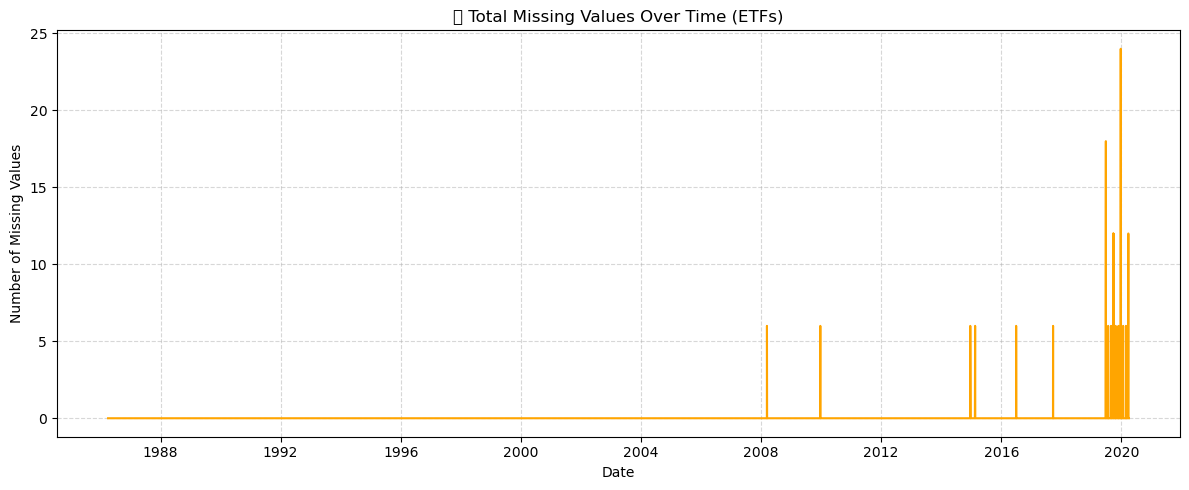

,Date,missing_count
0,1986-04-03,0
1,1986-04-04,0
2,1986-04-07,0
3,1986-04-08,0
4,1986-04-09,0
...,...,...
8564,2020-03-26,0
8565,2020-03-27,0
8566,2020-03-30,0
8567,2020-03-31,0


In [10]:
plot_missing_counts_over_time(all_etfs, label="ETFs")

In [11]:
def get_symbols_with_missing(all_etfs: dict, column: str):
    """
    Given a dict of DataFrames (key = symbol), return a list of symbols
    that have at least one missing value in the given column.
    """
    symbols = []

    for symbol, df in all_etfs.items():
        if column not in df.columns:
            raise ValueError(f"Column '{column}' not found in DataFrame for {symbol}")

        if df[column].isna().any():
            symbols.append(symbol)

    return sorted(symbols)


In [12]:
missing_open_symbols = get_symbols_with_missing(all_etfs, "Open")
missing_volume_symbols = get_symbols_with_missing(all_etfs, "Volume")
missing_high_symbols = get_symbols_with_missing(all_etfs, "High")
missing_low_symbols = get_symbols_with_missing(all_etfs, "Low")
missing_close_symbols = get_symbols_with_missing(all_etfs, "Close")
missing_adj_close_symbols = get_symbols_with_missing(all_etfs, "Adj Close")



In [13]:
print("Missing symbols for each column:\n")

print(f"Open:       {len(missing_open_symbols)} symbols")
print(missing_open_symbols[:20], "...\n" if len(missing_open_symbols) > 20 else "\n")

print(f"Volume:     {len(missing_volume_symbols)} symbols")
print(missing_volume_symbols[:20], "...\n" if len(missing_volume_symbols) > 20 else "\n")

print(f"High:       {len(missing_high_symbols)} symbols")
print(missing_high_symbols[:20], "...\n" if len(missing_high_symbols) > 20 else "\n")

print(f"Low:        {len(missing_low_symbols)} symbols")
print(missing_low_symbols[:20], "...\n" if len(missing_low_symbols) > 20 else "\n")

print(f"Close:      {len(missing_close_symbols)} symbols")
print(missing_close_symbols[:20], "...\n" if len(missing_close_symbols) > 20 else "\n")

print(f"Adj Close:  {len(missing_adj_close_symbols)} symbols")
print(missing_adj_close_symbols[:20], "...\n" if len(missing_adj_close_symbols) > 20 else "\n")


Missing symbols for each column:

Open:       11 symbols
['EDOW', 'EINC', 'JKL', 'PSM', 'REGL', 'RETL', 'RHS', 'RPV', 'SDOW', 'SHAG', 'TDV'] 

Volume:     11 symbols
['EDOW', 'EINC', 'JKL', 'PSM', 'REGL', 'RETL', 'RHS', 'RPV', 'SDOW', 'SHAG', 'TDV'] 

High:       11 symbols
['EDOW', 'EINC', 'JKL', 'PSM', 'REGL', 'RETL', 'RHS', 'RPV', 'SDOW', 'SHAG', 'TDV'] 

Low:        11 symbols
['EDOW', 'EINC', 'JKL', 'PSM', 'REGL', 'RETL', 'RHS', 'RPV', 'SDOW', 'SHAG', 'TDV'] 

Close:      11 symbols
['EDOW', 'EINC', 'JKL', 'PSM', 'REGL', 'RETL', 'RHS', 'RPV', 'SDOW', 'SHAG', 'TDV'] 

Adj Close:  11 symbols
['EDOW', 'EINC', 'JKL', 'PSM', 'REGL', 'RETL', 'RHS', 'RPV', 'SDOW', 'SHAG', 'TDV'] 



In [14]:
# Put all lists into a dictionary for convenience
missing_dict = {
    "Open": missing_open_symbols,
    "Volume": missing_volume_symbols,
    "High": missing_high_symbols,
    "Low": missing_low_symbols,
    "Close": missing_close_symbols,
    "Adj Close": missing_adj_close_symbols
}

# Convert lists to sets for easy comparison
missing_sets = {col: set(syms) for col, syms in missing_dict.items()}

# Take the first set as reference
first_col = list(missing_sets.keys())[0]
reference_set = missing_sets[first_col]

# Check if all sets match the reference
all_same = all(missing_sets[col] == reference_set for col in missing_sets)

print("---------------------------------------------------")
if all_same:
    print("✅ All columns have missing values in EXACTLY the same symbols.")
else:
    print("❌ Columns do NOT have missing values in the same symbols.\n")

    # Show which ones differ
    print("Differences:")
    for col, s in missing_sets.items():
        if s != reference_set:
            print(f"- {col} differs from {first_col}")


---------------------------------------------------
✅ All columns have missing values in EXACTLY the same symbols.


# 5. Cleaning Missing Values

Since only 0.5% of the stocks' symbols have missing values, we'll just remove them

In [15]:
def remove_missing_symbols(all_etfs: dict, symbols_to_remove: list):
    """
    Removes the given symbols from the all_stocks dict (in-place).

    Parameters
    ----------
    all_stocks : dict
        Dictionary where keys = stock symbols and values = DataFrames.
    symbols_to_remove : list
        List of symbols to delete from all_stocks.
    """
    for sym in symbols_to_remove:
        if sym in all_etfs:
            del all_etfs[sym]

symbols_to_remove = missing_open_symbols  # since they are all the same
remove_missing_symbols(all_etfs, symbols_to_remove)
print("Remaining symbols:", len(all_etfs))
print("Removed symbols:", len(symbols_to_remove))
print(type(all_etfs))



Remaining symbols: 2154
Removed symbols: 11
<class 'dict'>


## 6. Zero-value analysis

Zeros in price or volume columns can be problematic: they may represent bad data 

In this section we:

- measure how often each symbol has zero values;
- compute overall zero rates;
- plot the number of zeros over time for several columns:
  - `Open`
  - `Volume`
  - `Adj Close`
  - `Close`

This tells us whether zeros are rare anomalies or a systematic issue that needs cleaning.


In [16]:
zero_per_symbol_etfs, zero_overall_etfs = zero_rates_from_dict(all_etfs)
print(" Zero value rates per symbol (ETFs):")


print("\n Overall zero value rates (ETFs):")
print(zero_overall_etfs)


 Zero value rates per symbol (ETFs):

 Overall zero value rates (ETFs):
           Total Zero Rate (%)
Weekday              18.787439
Open                  0.036042
High                  0.000585
Low                   0.000585
Close                 0.000000
Adj Close             0.000000
Volume                5.382890


/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:175: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


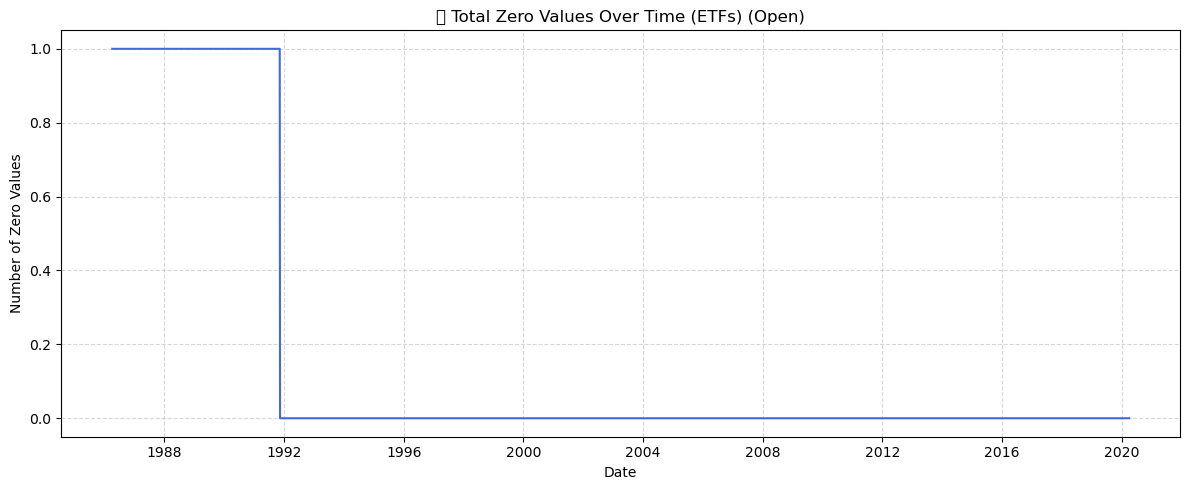

,Date,zero_count
0,1986-04-03,1
1,1986-04-04,1
2,1986-04-07,1
3,1986-04-08,1
4,1986-04-09,1
...,...,...
8563,2020-03-26,0
8564,2020-03-27,0
8565,2020-03-30,0
8566,2020-03-31,0


In [17]:
plot_zero_counts_over_time(all_etfs, label="ETFs",column="Open")


/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:175: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


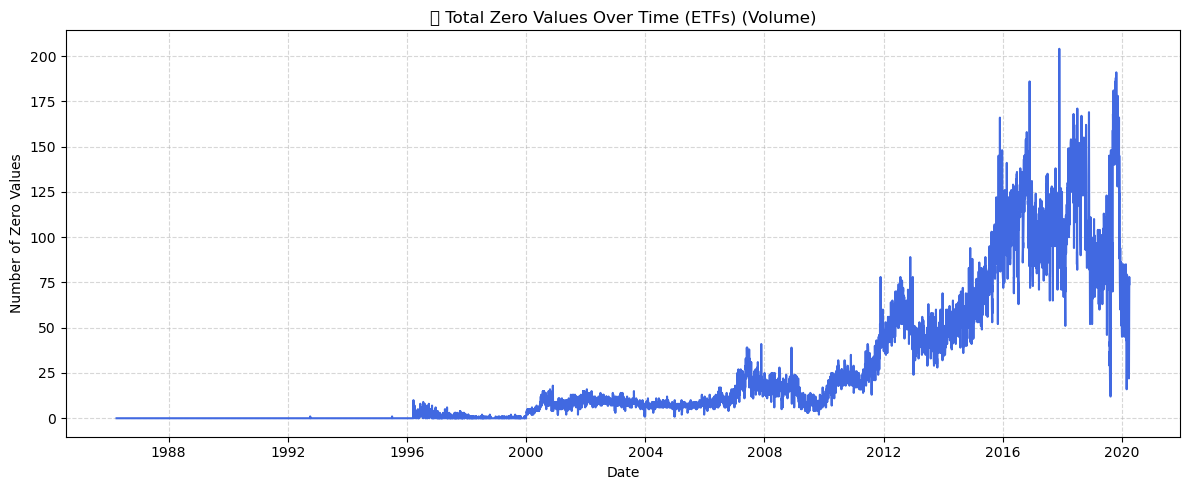

,Date,zero_count
0,1986-04-03,0
1,1986-04-04,0
2,1986-04-07,0
3,1986-04-08,0
4,1986-04-09,0
...,...,...
8563,2020-03-26,60
8564,2020-03-27,22
8565,2020-03-30,72
8566,2020-03-31,78


In [18]:
plot_zero_counts_over_time(all_etfs, label="ETFs",column="Volume")

/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:175: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


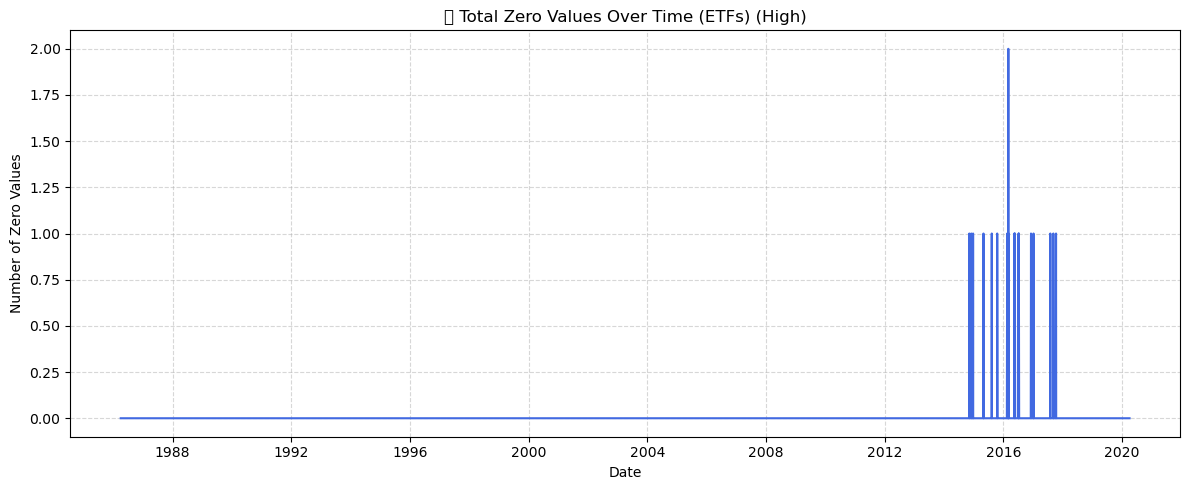

,Date,zero_count
0,1986-04-03,0
1,1986-04-04,0
2,1986-04-07,0
3,1986-04-08,0
4,1986-04-09,0
...,...,...
8563,2020-03-26,0
8564,2020-03-27,0
8565,2020-03-30,0
8566,2020-03-31,0


In [19]:
plot_zero_counts_over_time(all_etfs, label="ETFs",column="High")

/Users/chedliabdennebi/Desktop/ADA/projet/src/utils/data_inspection_viz.py:175: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/anaconda3/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128338 (\N{CLOCK FACE THREE OCLOCK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


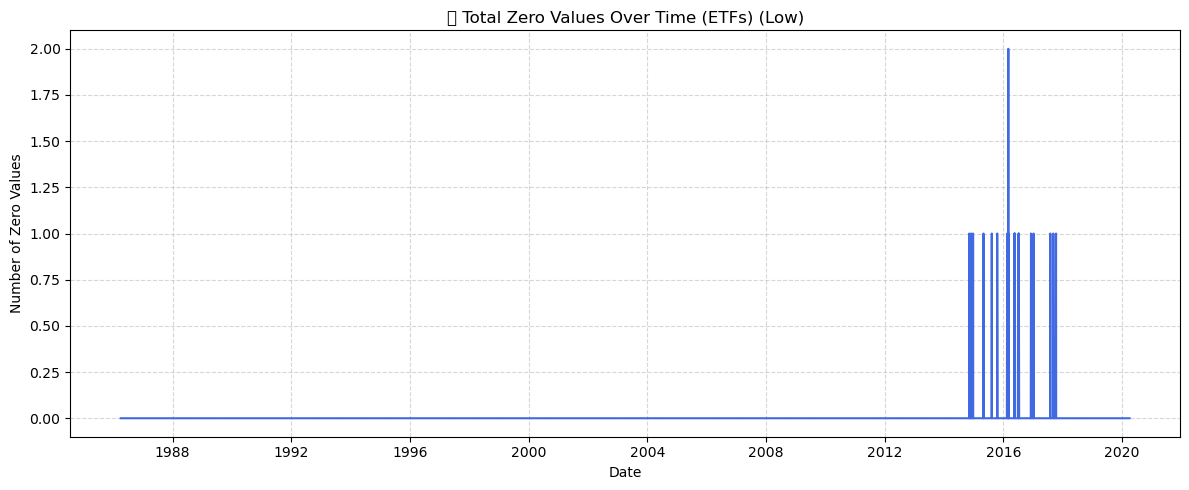

,Date,zero_count
0,1986-04-03,0
1,1986-04-04,0
2,1986-04-07,0
3,1986-04-08,0
4,1986-04-09,0
...,...,...
8563,2020-03-26,0
8564,2020-03-27,0
8565,2020-03-30,0
8566,2020-03-31,0


In [20]:
plot_zero_counts_over_time(all_etfs, label="ETFs",column="Low")

In [21]:
zero_symbols_high = get_symbols_with_zeros(all_etfs, "High")
print(zero_symbols_high)
zero_symbols_low = get_symbols_with_zeros(all_etfs, "Low")
print(zero_symbols_low)

['DVP', 'SYV']
['DVP', 'SYV']


In [22]:
zero_symbols_vol = get_symbols_with_zeros(all_etfs, "Volume")
print(zero_symbols_vol)

['AADR', 'AAXJ', 'ACES', 'ACIO', 'ACSG', 'ACSI', 'ACWF', 'ACWV', 'ADME', 'ADRE', 'AESR', 'AFIF', 'AFK', 'AFLG', 'AFMC', 'AFSM', 'AFTY', 'AGGP', 'AGGY', 'AGND', 'AGT', 'AGZ', 'AGZD', 'AIA', 'AIIQ', 'AIRR', 'ALFA', 'ALTS', 'ALTY', 'AMCA', 'AMOM', 'AMZA', 'ANGL', 'AOA', 'AOK', 'AOM', 'AOR', 'ARCM', 'ARGT', 'ARKG', 'ARKK', 'ARKQ', 'ARKW', 'ASEA', 'ASET', 'ASHS', 'ASHX', 'AVDV', 'AWTM', 'AXJL', 'BAPR', 'BATT', 'BAUG', 'BBAX', 'BBC', 'BBCA', 'BBEU', 'BBIN', 'BBJP', 'BBP', 'BBRE', 'BBSA', 'BCD', 'BCI', 'BDCY', 'BDEC', 'BDRY', 'BFEB', 'BFIT', 'BGRN', 'BIB', 'BIBL', 'BICK', 'BIS', 'BIZD', 'BJAN', 'BJK', 'BJUL', 'BJUN', 'BLES', 'BLHY', 'BND', 'BNDC', 'BNO', 'BNOV', 'BOCT', 'BOIL', 'BOSS', 'BOTZ', 'BRZU', 'BSAE', 'BSBE', 'BSCE', 'BSCK', 'BSCL', 'BSCM', 'BSCN', 'BSCO', 'BSCP', 'BSCQ', 'BSCR', 'BSCS', 'BSCT', 'BSDE', 'BSEP', 'BSJK', 'BSJL', 'BSJM', 'BSJN', 'BSJO', 'BSJP', 'BSJQ', 'BSJR', 'BSML', 'BSMM', 'BSMN', 'BSMO', 'BSMP', 'BSMQ', 'BSMR', 'BSMS', 'BSMT', 'BTAL', 'BTEC', 'BTYS', 'BUG', 'BUL', 'B

In [23]:
zero_symbols_close_adj = get_symbols_with_zeros(all_etfs, "Adj Close")
print(zero_symbols_close_adj)
zero_symbols_close = get_symbols_with_zeros(all_etfs, "Close")
print(zero_symbols_close)
print (zero_symbols_close_adj == zero_symbols_close)




[]
[]
True


## 6. Cleaning Zero Value Columns (`Open`, `Close`, `Adj Close`, `Volume` )

Using the information from the previous diagnostics, we now clean the price data:

1. Identify symbols where `Adj Close`, `Close`, `High`, `Low`  contain zeros.
2. Remove the worst symbols if they are too corrupted.
3. Fill remaining `Adj Close` gaps (NaNs) using a suitable rule.
4. Fix `Open` and `Close` when they are zero or inconsistent by using
   the `Adj Close` value from the previous or current day.
5. 
6. 


In [24]:
remove_missing_symbols(all_etfs, zero_symbols_high)


In [25]:
def fill_zero_open_with_prev_adj_close(all_stocks: dict):
    """
    For each symbol (DataFrame) in all_stocks:

    1. If the first row has Open == 0:
       - Store that day's Adj Close in a variable.
       - Drop the whole first row.
       - If the new first row still has Open == 0, replace it with the stored Adj Close.

    2. For the remaining rows where Open == 0:
       - Replace Open with the previous day's Adj Close.

    Assumptions:
    - No NaNs in 'Open' or 'Adj Close'.
    - We only want to fix zeros in 'Open'.

    Modifies all_stocks in-place.
    """
    for symbol, df in all_stocks.items():
        if df.empty:
            continue

        # Ensure sorted by Date (just in case)
        if "Date" in df.columns:
            df.sort_values("Date", inplace=True)

        if "Open" not in df.columns or "Adj Close" not in df.columns:
            continue

        # --- Step 1: handle first row if Open == 0 ---
        if df["Open"].iloc[0] == 0:
            first_idx = df.index[0]
            first_adj_close = df.loc[first_idx, "Adj Close"]

            # Drop the original first row completely
            df.drop(first_idx, inplace=True)

            # If everything is gone, move to next symbol
            if df.empty:
                continue

            # Re-check the new first row
            new_first_idx = df.index[0]
            if df.loc[new_first_idx, "Open"] == 0:
                df.loc[new_first_idx, "Open"] = first_adj_close

        # --- Step 2: fix remaining zeros using previous Adj Close ---
        open_zero_mask = (df["Open"] == 0)

        if not open_zero_mask.any():
            continue

        prev_adj_close = df["Adj Close"].shift(1)
        df.loc[open_zero_mask, "Open"] = prev_adj_close[open_zero_mask]


In [26]:
fill_zero_open_with_prev_adj_close(all_etfs)


In [27]:
def trim_leading_zero_volumes(all_etfs):
    """
    For each symbol, remove rows at the beginning where Volume == 0
    until the first non-zero Volume is found.
    """
    for symbol, df in all_etfs.items():
        if 'Volume' not in df.columns:
            raise ValueError(f"Symbol {symbol} has no 'Volume' column")

        nonzero_idx = df.index[df['Volume'] > 0]

        # if the stock has at least one non-zero volume
        if len(nonzero_idx) > 0:
            first_idx = nonzero_idx[0]
            all_etfs[symbol] = df.loc[first_idx:].copy()
        # else: all volumes are 0 → we leave it as is (or you can drop the symbol)
        

trim_leading_zero_volumes(all_etfs)

In [28]:
def add_volatility(all_stocks):
    for symbol, df in all_stocks.items():
        df["Volatility"] = (df["High"] - df["Low"]) / df["Open"]


In [29]:
add_volatility(all_etfs)


In [30]:
import numpy as np
import pandas as pd

def fill_zero_volumes_past_only(all_stocks, n_same_weekday=10, vol_weight=0.7):
    """
    For each symbol DataFrame in all_stocks:

    - For each row with Volume == 0:
        baseline = median of past non-zero Volume on same Weekday
        if none: baseline = median of all past non-zero Volume
        filled_volume = baseline * (1 + vol_z * vol_weight)

    - vol_z is the z-score of Volatility for that symbol.
    - Uses ONLY past data (no future).

    Assumes columns: 'Weekday', 'Volume', 'Volatility'.
    Changes are IN PLACE.
    """

    for symbol, df in all_stocks.items():

        # --- check required columns ---
        for col in ['Weekday', 'Volume', 'Volatility']:
            if col not in df.columns:
                raise ValueError(f"{symbol}: missing column '{col}'")

        # --- volatility z-score (as a Series, no extra column) ---
        vol_mean = df['Volatility'].mean()
        vol_std  = df['Volatility'].std()

        if vol_std == 0 or np.isnan(vol_std):
            vol_z = pd.Series(0.0, index=df.index)
        else:
            vol_z = (df['Volatility'] - vol_mean) / vol_std

        # indices where Volume == 0
        zero_idx = df.index[df['Volume'] == 0]

        for idx in zero_idx:

            weekday = df.at[idx, 'Weekday']

            # all past rows (strictly before idx)
            past = df.loc[:idx-1]

            # 1) past non-zero same weekday
            past_same = past[(past['Weekday'] == weekday) &
                             (past['Volume'] > 0)]['Volume']

            if len(past_same) > 0:
                base_source = past_same.tail(n_same_weekday)
            else:
                # 2) fallback: all past non-zero volumes (any weekday)
                past_nonzero = past[past['Volume'] > 0]['Volume']
                if len(past_nonzero) == 0:
                    # no past info at all -> leave Volume at 0 for this row
                    continue
                base_source = past_nonzero.tail(n_same_weekday)

            baseline = base_source.median()

            # volatility adjustment
            adj = 1 + vol_z.at[idx] * vol_weight
            if adj < 0.01:
                adj = 0.01

            df.at[idx, 'Volume'] = baseline * adj


In [31]:
fill_zero_volumes_past_only(all_etfs)

/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_27745/3275087269.py:67: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '524.0059781762855' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.at[idx, 'Volume'] = baseline * adj
/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_27745/3275087269.py:67: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '1013.0182198606736' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df.at[idx, 'Volume'] = baseline * adj
/var/folders/z8/rtml_vtn47g7d8xsd6ctbs8m0000gn/T/ipykernel_27745/3275087269.py:67: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '4480.178320285562' has dtype incompatible with int64, please explicitly

# 7.Check

In [32]:
zero_per_symbol_etfs, zero_overall_etfs = zero_rates_from_dict(all_etfs)
print(" Zero value rates per symbol (ETFs):")


print("\n Overall zero value rates (ETfs):")
print(zero_overall_etfs)




 Zero value rates per symbol (ETFs):

 Overall zero value rates (ETfs):
            Total Zero Rate (%)
Weekday               18.787409
Open                   0.000000
High                   0.000000
Low                    0.000000
Close                  0.000000
Adj Close              0.000000
Volume                 0.000000
Volatility             8.461170


In [33]:
missing_per_etf, missing_etfs = missing_rates_from_dict(all_etfs)

print(" Missing rates per etf:")
print(missing_per_etf.head())

print("\n Overall missing rates for etfs:")
print(missing_etfs)

 Missing rates per etf:
        Date  Weekday  Open  High  Low  Close  Adj Close  Volume  Symbol  \
Symbol                                                                     
AAAU     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0   
AADR     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0   
AAXJ     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0   
ABEQ     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0   
ACES     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0   

        Volatility  
Symbol              
AAAU           0.0  
AADR           0.0  
AAXJ           0.0  
ABEQ           0.0  
ACES           0.0  

 Overall missing rates for etfs:
            Total Missing Rate (%)
Date                           0.0
Weekday                        0.0
Open                           0.0
High                           0.0
Low                            0.0
Close                          0.0
Adj Close        

In [34]:
missing_open_symbols = get_symbols_with_missing(all_etfs, "Open")
print(missing_open_symbols)
remove_missing_symbols(all_etfs, missing_open_symbols)


[]


# Last Check

In [35]:
missing_per_etf, missing_etfs = missing_rates_from_dict(all_etfs)

print(" Missing rates per stock:")
print(missing_per_etf.head())

print("\n Overall missing rates for stocks:")
print(missing_etfs)

 Missing rates per stock:
        Date  Weekday  Open  High  Low  Close  Adj Close  Volume  Symbol  \
Symbol                                                                     
AAAU     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0   
AADR     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0   
AAXJ     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0   
ABEQ     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0   
ACES     0.0      0.0   0.0   0.0  0.0    0.0        0.0     0.0     0.0   

        Volatility  
Symbol              
AAAU           0.0  
AADR           0.0  
AAXJ           0.0  
ABEQ           0.0  
ACES           0.0  

 Overall missing rates for stocks:
            Total Missing Rate (%)
Date                           0.0
Weekday                        0.0
Open                           0.0
High                           0.0
Low                            0.0
Close                          0.0
Adj Close    

In [36]:
zero_per_symbol_etfs, zero_overall_etfs = zero_rates_from_dict(all_etfs)
print(" Zero value rates per symbol (ETFs):")


print("\n Overall zero value rates (ETFs):")
print(zero_overall_etfs)


 Zero value rates per symbol (ETFs):

 Overall zero value rates (ETFs):
            Total Zero Rate (%)
Weekday               18.787409
Open                   0.000000
High                   0.000000
Low                    0.000000
Close                  0.000000
Adj Close              0.000000
Volume                 0.000000
Volatility             8.461170
